In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../dataset/monthly_spending.csv", parse_dates=["month"])
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate user-month-category rows:", df.duplicated(["user_id", "month", "category"]).sum())
df.head()

Shape: (11880, 4)
Missing values: 0
Duplicate user-month-category rows: 0


,user_id,month,category,amount
0,U01,2023-11-01,Bills & Utilities,2625.0
1,U01,2023-11-01,Entertainment,1062.0
2,U01,2023-11-01,Food,6011.0
3,U01,2023-11-01,Groceries,6491.0
4,U01,2023-11-01,Health,2181.0


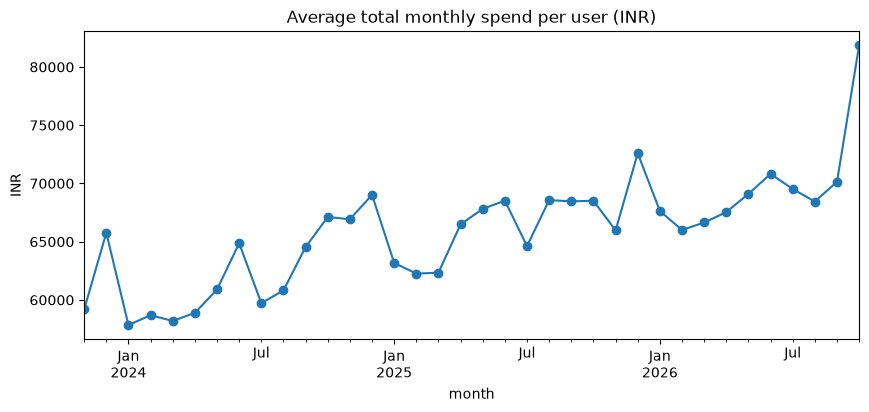

In [2]:
total = df.groupby("month")["amount"].sum() / df["user_id"].nunique()

fig, ax = plt.subplots(figsize=(10, 4))
total.plot(ax=ax, marker="o")
ax.set_title("Average total monthly spend per user (INR)")
ax.set_ylabel("INR")
plt.show()

In [3]:
year = np.where(df["month"] < "2024-11-01", "Year 1",
        np.where(df["month"] < "2025-11-01", "Year 2", "Year 3"))
avg = df.assign(year=year).groupby("year")["amount"].sum() / df["user_id"].nunique() / 12
print(avg.round(0))

year
Year 1    61374.0
Year 2    66390.0
Year 3    69690.0
Name: amount, dtype: float64


month
1     0.97
2     0.96
3     0.96
4     0.99
5     1.00
6     1.03
7     0.98
8     0.99
9     1.01
10    1.07
11    1.00
12    1.08
Name: ratio, dtype: float64


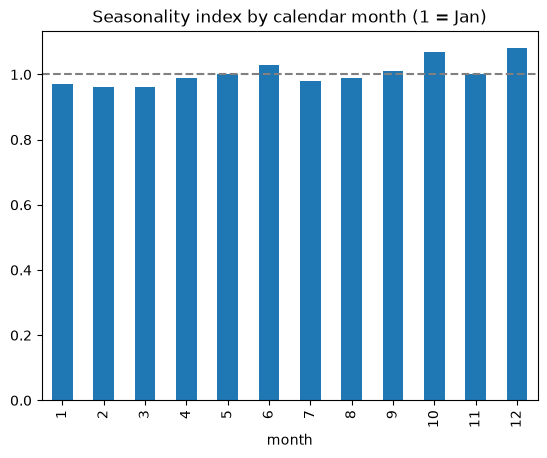

In [4]:
t = df.groupby("month")["amount"].sum().reset_index()
t["trend"] = t["amount"].rolling(12, center=True, min_periods=6).mean()
t["ratio"] = t["amount"] / t["trend"]
season = t.groupby(t["month"].dt.month)["ratio"].mean().round(2)
print(season)
season.plot(kind="bar", title="Seasonality index by calendar month (1 = Jan)")
plt.axhline(1, color="gray", linestyle="--")
plt.show()

In [5]:
cat = df.groupby("category")["amount"].agg(["mean", "std"])
cat["variability"] = (cat["std"] / cat["mean"]).round(2)
cat.round(0).sort_values("mean", ascending=False)

,mean,std,variability
category,,,
Rent,20762.0,6648.0,0.0
Shopping,9046.0,6839.0,1.0
Groceries,8591.0,3145.0,0.0
Travel,6044.0,5841.0,1.0
Food,5986.0,2271.0,0.0
Other,4135.0,2678.0,1.0
Transport,3616.0,1434.0,0.0
Bills & Utilities,3019.0,1210.0,0.0
Health,1974.0,1337.0,1.0


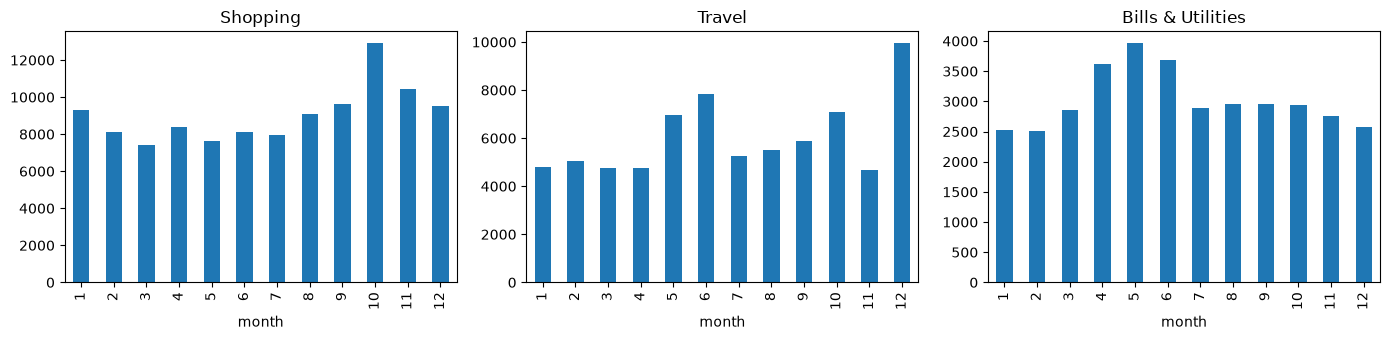

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["Shopping", "Travel", "Bills & Utilities"]):
    df[df["category"] == c].groupby(df["month"].dt.month)["amount"].mean().plot(kind="bar", ax=ax, title=c)
plt.tight_layout()
plt.show()

In [7]:
per_user = df.groupby(["user_id", "month"])["amount"].sum().groupby("user_id").mean()
print("Lowest-spending user: ", round(per_user.min()))
print("Highest-spending user:", round(per_user.max()))

Lowest-spending user:  42297
Highest-spending user: 119596


In [8]:
rent = df[(df["user_id"] == "U01") & (df["category"] == "Rent")].set_index("month")["amount"]
rent[rent.diff() != 0]

month
2023-11-01    17000.0
2024-11-01    18100.0
2025-11-01    19300.0
Name: amount, dtype: float64